# Evidence Lens: scientific abstract retrieval

Which retriever finds relevant scientific abstracts: lexical BM25, a pretrained neural encoder, or their combination?

This notebook evaluates all **5,183 documents** and all **300 BEIR SciFact test queries**. It is document retrieval, not entailment, claim verification, an LLM answer generator, or medical advice. The encoder is pretrained; no fine-tuning happens here.

We use BEIR train judgments only to select hybrid parameters. BEIR test corresponds to the original SciFact labeled development set, **not the original hidden test**. Test diagnostics are descriptive and never feed selection.

## 1. Sources and protocol

[SciFact, Wadden et al. (2020)](https://aclanthology.org/2020.emnlp-main.609/) supplies claims and abstracts; [BEIR](https://github.com/beir-cellar/beir) packages document-relevance judgments. Claims/evidence: CC BY 4.0; original abstracts: ODC-By 1.0; BEIR dataset card: CC BY-SA 4.0. See [licensing notes](../docs/sources-and-licenses.md).

The archive is verified against BEIR's published MD5 on every read. MiniLM's actual Hugging Face revision is pinned. Corpus vectors are cached by full input text, model revision and preprocessing policy. MD5 is an upstream integrity check, not a cryptographic authenticity guarantee.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'evidence_lens').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from evidence_lens.data import load_data, load_qrels, MODEL, REVISION, MD5
from evidence_lens.retrieval import Retriever, fuse, tokenize
from evidence_lens.metrics import evaluate
from evidence_lens.experiment import select_hybrid
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
print({'model': MODEL, 'revision': REVISION, 'archive_md5': MD5})

{'model': 'sentence-transformers/all-MiniLM-L6-v2', 'revision': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'archive_md5': '5f7d1de60b170fc8027bb7898e2efca1'}


## 2. Load the benchmark and inspect the development data

`corpus` has `_id`, `title`, `text`, and metadata. `queries` maps claim IDs to text. Qrels map query IDs to relevant corpus IDs with positive relevance grades. The corpus is the fixed search collection, so BM25's document-frequency statistics legitimately use the entire collection. No labels enter either retriever.

We inspect development judgments before choosing the hybrid. Merely loading the unlabeled query mapping does not select on test outcomes.

In [2]:
corpus, queries = load_data()
development = load_qrels('train')
assert len(corpus) == 5183
assert all(q in queries for q in development)
corpus_ids = {d['_id'] for d in corpus}
assert all(d in corpus_ids for rel in development.values() for d in rel)
quality = {'documents': len(corpus), 'all_queries': len(queries), 'development_queries': len(development),
           'missing_titles': sum(not d['title'].strip() for d in corpus),
           'missing_abstracts': sum(not d['text'].strip() for d in corpus),
           'duplicate_ids': len(corpus) - len(corpus_ids)}
display(pd.Series(quality, name='count'))
display(pd.Series([len(r) for r in development.values()]).value_counts().rename('development queries by relevant-document count'))
display(pd.DataFrame(corpus)[['_id', 'title']].head(3))

documents              5183
all_queries            1109
development_queries     809
missing_titles            0
missing_abstracts         0
duplicate_ids             0
Name: count, dtype: int64

1    732
2     53
3     16
4      7
5      1
Name: development queries by relevant-document count, dtype: int64

,_id,title
0,4983,Microstructural development of human newborn c...
1,5836,Induction of myelodysplasia by myeloid-derived...
2,7912,"BC1 RNA, the transcript from a master gene for..."


,abstract words
count,5183.000000
mean,201.810920
std,86.007594
min,26.000000
50%,192.000000
90%,295.000000
99%,451.540000
max,1524.000000


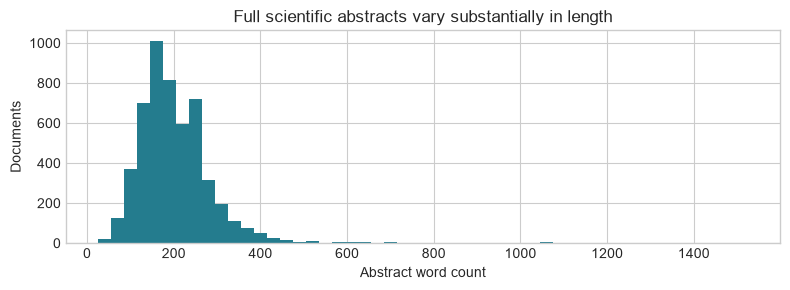

In [3]:
word_lengths = pd.Series([len(d['text'].split()) for d in corpus])
display(word_lengths.describe(percentiles=[.5, .9, .99]).to_frame('abstract words'))
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(word_lengths, bins=50, color='#247c8e')
ax.set(xlabel='Abstract word count', ylabel='Documents', title='Full scientific abstracts vary substantially in length')
fig.tight_layout()
(ROOT / 'outputs/figures').mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / 'outputs/figures/abstract_lengths.png', dpi=150)
plt.show()

## 3. Baseline and neural representations

**BM25:** lowercase Unicode word tokens; `rank_bm25` defaults `k1=1.5`, `b=0.75`; no stemming or stop-word removal. This preserves scientific terms and provides an auditable lexical baseline.

**MiniLM:** title + space + full abstract, encoded to normalized 384-dimensional vectors. Dot product is cosine similarity. Inputs are truncated to **256 wordpieces**, including special tokens; the full abstract remains visible in the app. We measure truncation rather than implying that the encoder reads every abstract in full. No chunking, training or domain adaptation is implemented.

Exact search is adequate at 5,183 documents. Ties resolve by lexicographic corpus ID. Four CPU torch threads are used unless CUDA is available. Timings separate index/model setup from batched query encoding/search; they are not production latency guarantees.

In [4]:
retriever = Retriever(corpus)
print({'device': retriever.device, 'embedding_shape': retriever.embeddings.shape,
       'embedding_cache_hit': retriever.cache_hit, **retriever.timings})
lengths = [len(x) for x in retriever.model.tokenizer(retriever.texts, truncation=False, verbose=False)['input_ids']]
print({'truncated_documents': sum(n > 256 for n in lengths), 'total_documents': len(lengths), 'max_input_wordpieces': max(lengths)})

C:\Users\itsar\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12806.09it/s]

C:\Users\itsar\ai-system-design-projects\evidence-lens\evidence_lens\retrieval.py:80: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  expected_dimension=self.model.get_sentence_embedding_dimension())


{'device': 'cpu', 'embedding_shape': (5183, 384), 'embedding_cache_hit': True, 'bm25_build_seconds': 0.4023574999300763, 'model_load_seconds': 5.138342100079171, 'corpus_encode_or_cache_seconds': 0.03425300004892051}


{'truncated_documents': 3681, 'total_documents': 5183, 'max_input_wordpieces': 1939}


## 4. Select hybrid fusion using development judgments only

We retrieve the top 100 candidates from each method and fuse their ranks:

$$s(d) = \frac{1-w}{k+r_{BM25}(d)} + \frac{w}{k+r_{dense}(d)}.$$

Missing candidates contribute zero. Search grid: `k ∈ {10,30,60}`, dense weight `w ∈ {0.25,0.5,0.75}`. Select highest development nDCG@10; exact ties choose lower k, then lower dense weight. These choices were fixed before held-out evaluation.

All metrics are macro-averages over qrels queries, including queries with no retrieved positives. nDCG uses gain `2^relevance−1`; MRR@10 is reciprocal first relevant rank or zero. Recall's denominator is **all judged relevant documents**, not retrieved positives. Unjudged results count as nonrelevant; incomplete judgments remain a limitation.

In [5]:
dev_sparse, dev_dense, dev_timing = retriever.retrieve({q: queries[q] for q in development})
selected, grid = select_hybrid(dev_sparse, dev_dense, development)
display(pd.DataFrame(grid))
print('Frozen selection:', selected)
# This file is written before test judgments are opened in this notebook.
(ROOT / 'outputs/notebook_selection.json').write_text(json.dumps(selected, indent=2))
print(dev_timing)

,k,weight,nDCG@10,MRR@10,Recall@10,Recall@100
0,10,0.25,0.686367,0.656151,0.800906,0.947013
1,10,0.50,0.703864,0.666365,0.839637,0.952822
2,10,0.75,0.683320,0.650152,0.804924,0.952204
3,30,0.25,0.687664,0.655915,0.808426,0.937124
4,30,0.50,0.695575,0.660035,0.825628,0.952822
5,30,0.75,0.683556,0.649611,0.806675,0.952204
6,60,0.25,0.689529,0.656325,0.815225,0.907664
7,60,0.50,0.691575,0.656409,0.819448,0.952822
8,60,0.75,0.684833,0.648924,0.816461,0.932427


Frozen selection: {'k': 10, 'weight': 0.5, 'selection_split': 'BEIR train', 'objective': 'nDCG@10', 'candidate_depth': 100}
{'bm25_seconds': 13.579339399933815, 'dense_encode_and_search_seconds': 2.57710960006807, 'query_count': 809, 'mode': 'batched throughput, not single-request latency'}


## 5. Open held-out judgments only after freezing selection

This is a reproducibility rerun of the same frozen experiment, not another tuning opportunity. We report all three predeclared methods on all 300 queries. Re-execution must match the committed selection and metric report within numerical tolerance.

In [6]:
test = load_qrels('test')
assert len(test) == 300 and not set(test) & set(development)
sparse, dense, test_timing = retriever.retrieve({q: queries[q] for q in test})
hybrid = {q: fuse(sparse[q], dense[q], k=selected['k'], weight=selected['weight']) for q in test}
runs = {'BM25': sparse, 'MiniLM': dense, 'Hybrid RRF': hybrid}
comparison = pd.DataFrame({name: evaluate(run, test) for name, run in runs.items()}).T
display(comparison.round(4))
print(test_timing)
report = json.loads((ROOT / 'outputs/report.json').read_text())
assert selected == report['selected_hybrid']
for name in runs:
    np.testing.assert_allclose(comparison.loc[name].values, list(report['metrics'][name].values()), atol=1e-8)
print('Verified: notebook rankings reproduce the pipeline metrics.')

,nDCG@10,MRR@10,Recall@10,Recall@100
BM25,0.6519,0.6186,0.7740,0.8731
MiniLM,0.6451,0.6047,0.7833,0.9250
Hybrid RRF,0.6967,0.6573,0.8374,0.9577


{'bm25_seconds': 4.734692099969834, 'dense_encode_and_search_seconds': 1.0385601000161842, 'query_count': 300, 'mode': 'batched throughput, not single-request latency'}
Verified: notebook rankings reproduce the pipeline metrics.


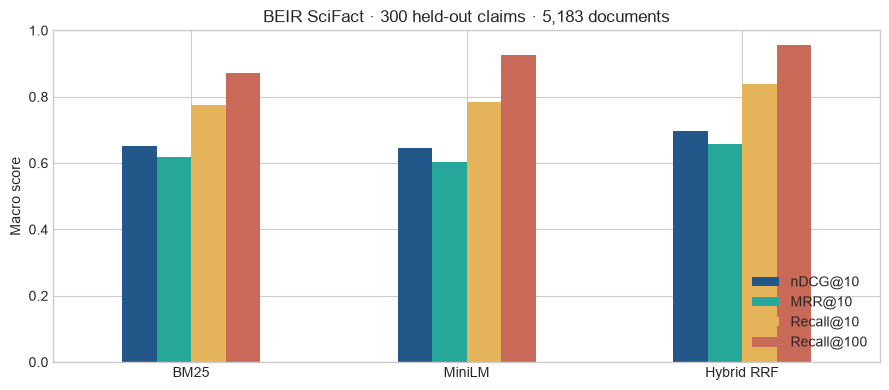

Highest observed test nDCG@10: Hybrid RRF. This observation does not retune the deployed hybrid.


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
comparison.plot.bar(ax=ax, rot=0, color=['#235789', '#27a69a', '#e5b45a', '#c86a57'])
ax.set(ylabel='Macro score', ylim=(0, 1), title='BEIR SciFact · 300 held-out claims · 5,183 documents')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(ROOT / 'outputs/figures/retrieval_comparison.png', dpi=150)
plt.show()
best = comparison['nDCG@10'].idxmax()
print(f'Highest observed test nDCG@10: {best}. This observation does not retune the deployed hybrid.')

## 6. Leakage, denominator and length audit

Official splits are retained. We normalize claims to lowercase word-token sequences and check cross-split duplicates after policy selection. A non-overlap sensitivity report is recorded in the pipeline audit. Query ID disjointness does not establish pretraining decontamination: the encoder's upstream training includes scientific citation pairs and may overlap this benchmark. This project makes no clean-room generalization claim.

In [8]:
audit = report['audit']
display(pd.Series({k: v for k, v in audit.items() if k not in ['nonoverlap_sensitivity', 'wordpiece_length_quantiles']}, dtype=object))
display(pd.DataFrame(audit['nonoverlap_sensitivity']).T)
print('Full pipeline timing breakdown:')
display(report['timings'])

corpus_documents                                                             5183
queries_total                                                                1109
development_queries                                                           809
test_queries                                                                  300
train_test_normalized_text_overlap                                    [870, 1292]
normalization                              lowercase word tokens joined by spaces
empty_titles                                                                    0
empty_abstracts                                                                 0
duplicate_corpus_texts                                                          0
max_sequence_length                                                           256
documents_truncated                                                          3681
test_relevant_documents_per_query     {'1': 277, '2': 14, '3': 4, '4': 3, '5': 2}
dtype: object

,nDCG@10,MRR@10,Recall@10,Recall@100
BM25,0.652912,0.619411,0.775839,0.875559
MiniLM,0.646055,0.605428,0.785235,0.924497
Hybrid RRF,0.697991,0.658320,0.839653,0.957383


Full pipeline timing breakdown:


{'index': {'bm25_build_seconds': 0.5971791000338271,
  'model_load_seconds': 2.1423683000029996,
  'corpus_encode_or_cache_seconds': 120.41299009998329},
 'development': {'bm25_seconds': 13.220057899947278,
  'dense_encode_and_search_seconds': 2.5385886000003666,
  'query_count': 809,
  'mode': 'batched throughput, not single-request latency'},
 'test': {'bm25_seconds': 4.860404800041579,
  'dense_encode_and_search_seconds': 1.0485608000308275,
  'query_count': 300,
  'mode': 'batched throughput, not single-request latency',
  'rrf_fusion_seconds': 0.018652200000360608}}

## 7. Error analysis: wins, regressions and complete misses

Select cases deterministically by per-query nDCG delta (hybrid minus BM25), not by manually choosing favorable anecdotes. A retrieved paper can share scientific vocabulary yet fail on population, intervention, direction of effect or evidence type. Relevance judgments here cannot certify the truth of the claim.

In [9]:
rows = []
for q, rel in test.items():
    row = {'query_id': q, 'claim': queries[q]}
    for name, run in runs.items():
        row[name] = evaluate({q: run[q]}, {q: rel})['nDCG@10']
    row['hybrid_minus_BM25'] = row['Hybrid RRF'] - row['BM25']
    rows.append(row)
errors = pd.DataFrame(rows).sort_values(['hybrid_minus_BM25', 'query_id'])
display(errors.head(3))
display(errors.tail(3))
print('Hybrid zero-nDCG@10 claims:', int((errors['Hybrid RRF'] == 0).sum()))
lookup = {d['_id']: d for d in corpus}
for q in [errors.iloc[0]['query_id'], errors.iloc[-1]['query_id']]:
    print('\nCLAIM:', queries[q])
    print('JUDGED RELEVANT:', [(d, lookup[d]['title']) for d in test[q]])
    print('TOP RESULT BY METHOD:', {name: (run[q][0], lookup[run[q][0]]['title']) for name, run in runs.items()})

,query_id,claim,BM25,MiniLM,Hybrid RRF,hybrid_minus_BM25
292,1363,Venules have a thinner or absent smooth layer ...,1.0,0.000000,0.430677,-0.569323
143,674,LDL cholesterol has no involvement in the deve...,1.0,0.333333,0.430677,-0.569323
219,1024,Recurrent mutations occur frequently within CT...,1.0,0.000000,0.500000,-0.500000


,query_id,claim,BM25,MiniLM,Hybrid RRF,hybrid_minus_BM25
104,514,High dietary calcium intakes are unnecessary f...,0.00000,1.0,0.63093,0.63093
124,575,In domesticated populations of Saccharomyces c...,0.00000,0.5,0.63093,0.63093
15,72,Activator-inhibitor pairs are provided dorsall...,0.30103,1.0,1.00000,0.69897


Hybrid zero-nDCG@10 claims: 44

CLAIM: Venules have a thinner or absent smooth layer compared to arterioles.
JUDGED RELEVANT: [('8290953', 'Scaffold-based three-dimensional human fibroblast culture provides a structural matrix that supports angiogenesis in infarcted heart tissue.')]
TOP RESULT BY METHOD: {'BM25': ('8290953', 'Scaffold-based three-dimensional human fibroblast culture provides a structural matrix that supports angiogenesis in infarcted heart tissue.'), 'MiniLM': ('25175997', 'Pulmonary vascular lesions in end-stage idiopathic pulmonary fibrosis: Histopathologic study on lung explant specimens and correlations with pulmonary hemodynamics.'), 'Hybrid RRF': ('79447', 'Arteriolar function in visceral adipose tissue is impaired in human obesity.')}

CLAIM: Activator-inhibitor pairs are provided dorsally by Admpchordin.
JUDGED RELEVANT: [('6076903', 'Regulation of ADMP and BMP2/4/7 at Opposite Embryonic Poles Generates a Self-Regulating Morphogenetic Field')]
TOP RESULT BY MET

## 8. Practical interpretation and limits

The hybrid combines independent lexical and pretrained neural rankings without training a new model. Its parameters are chosen on BEIR train judgments. The observed comparison above—not an assumption that neural is always better—determines the scientific conclusion.

- Small, English biomedical/scientific benchmark; no current-literature coverage guarantee.
- Abstract retrieval only; no full-paper ingestion, citation verification, support/refutation classification or generated answers.
- Truncation loses late-abstract details. Chunking and a domain encoder are untested future alternatives, not implemented features.
- Incomplete qrels penalize unjudged but possibly relevant documents. No calibrated confidence or relevance threshold is provided; every valid query receives ranked candidates.
- No repeated hardware measurements, uncertainty intervals, production load tests or statistical-significance claims.
- The local Streamlit app shows title, full source abstract and corpus ID. Dataset/paper citation links are provided; document URLs are deliberately not guessed.

## 9. Practices checklist

| Practice | Status / rationale |
|---|---|
| Real full dataset | 5,183 verified corpus records; full 809 development and 300 test queries |
| Data integrity | Published MD5 checked on every cached ZIP read |
| Baseline | Token BM25 before pretrained MiniLM and RRF |
| Held-out selection | Nine RRF settings selected using train qrels only |
| Scaling / imputation | Not applicable to text retrieval; no numeric feature fitting |
| Fine-tuning | Not performed; do not interpret this as a trained SciFact model |
| Cache reproducibility | Text/model/policy fingerprint and pinned revision |
| Leakage audit | Query IDs and normalized claim overlap; pretraining overlap unknown |
| Tests | Metric denominators, ties, invalid input, cache changes, real Streamlit AppTest |
| Runtime verification | Full pipeline and this notebook executed; recorded results checked |
| Deployment | Local Streamlit; no auth, multi-user service, or production monitoring |

See the [README](../README.md) for commands and [system design](../docs/design.md) for implementation boundaries.